In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field
import os


In [2]:
apikey = os.getenv("GROQ_API_KEY")

In [3]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=apikey
)

In [ ]:
#if sentiment == "positive"
#LLM => positive, negative

In [4]:
class SentimentSchema(BaseModel):
    sentiment : Literal["positive","negative"] = Field(description="The sentiment of the text, either positive or negative.")

In [22]:
#issue_type
#tone
#urgency
class DiagnosSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [23]:
structured_model = llm.with_structured_output(SentimentSchema)
structured_model2 = llm.with_structured_output(DiagnosSchema)

In [25]:
structured_model2.invoke("I hatee this product! It's poor.I need urgent assistance otherwise i will raise higher complaint").model_dump()

{'issue_type': 'Support', 'tone': 'angry', 'urgency': 'high'}

In [10]:
structured_model.invoke("I hatee this product! It's poor.").sentiment

'negative'

In [14]:
class ReviewState(TypedDict):
    review : str
    sentiment : Literal["positive","negative"]
    diagnose : dict
    response : str

In [45]:
def find_sentiment(state:ReviewState):
    prompt = f"Find the sentiment of the followwing review {state['review']}"
    sentiment = structured_model.invoke(prompt).sentiment

    return {"sentiment":sentiment}

def check_condition(state:ReviewState) -> Literal["positive_response","run_diagnose"]:
    if state["sentiment"]=="potive":
        return "positive_response"
    else:
        return "run_diagnose"

def positive_response(state:ReviewState):
    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
    Also, kindly ask the user to leave feedback on our website."""

    response = llm.invoke(prompt)
    return {"response":response}

def run_diagnose(state:ReviewState):
    prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
    """
    response = structured_model2.invoke(prompt)

    return {"diagnose":response.model_dump()}

def negative_response(state:ReviewState):
    diagnose = state["diagnose"]
    prompt = f"""You are a support assistant.
    The user had a '{diagnose['issue_type']}' issue, sounded '{diagnose['tone']}', and marked urgency as '{diagnose['urgency']}'.
    Write an empathetic, helpful resolution message.
    """
    response = llm.invoke(prompt)

    return {"response":response}
    

In [46]:
graph = StateGraph(ReviewState)

graph.add_node("find_sentiment",find_sentiment)
graph.add_node("run_diagnose",run_diagnose)
graph.add_node("positive_response",positive_response)
graph.add_node("negative_response",negative_response)
graph.add_edge(START,"find_sentiment")
#conditional ==> positive or  negative
graph.add_conditional_edges("find_sentiment",check_condition)
graph.add_edge("positive_response",END)
graph.add_edge("run_diagnose","negative_response")
graph.add_edge("negative_response",END)


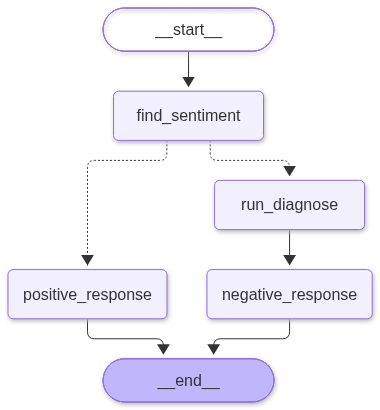

In [47]:
workflow = graph.compile()
workflow

In [48]:
intial_state={
    'review': "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}
workflow.invoke(intial_state)

{'review': 'I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality.',
 'sentiment': 'negative',
 'diagnose': {'issue_type': 'Bug', 'tone': 'frustrated', 'urgency': 'high'},
 'response': AIMessage(content='Hi there,\n\nI’m really sorry you’re running into this issue and I understand how frustrating it can be—especially when it’s happening right now. Let’s get it sorted out as quickly as possible.\n\n### Quick steps to try right away\n\n1. **Restart the app**  \n   Close it completely (remove it from recent apps) and open it again.  \n2. **Clear the cache**  \n   - Android: Settings\u202f→\u202fApps\u202f→\u202f[Your App]\u202f→\u202fStorage\u202f→\u202fClear Cache  \n   - iOS: Settings\u202f→\u202fGeneral\u202f→\u202fiPhone Storage\u202f→\u202f[Your App]\u202f→\u202fOffload App (then reinstall)  \n3. **Check for up